# 01 - Lectura y discovery

**TP2 - Módulo 2:** predecir si una persona es fumadora (`smoking`) a partir de datos de salud. La métrica de éxito es el **F1-score de la clase 1**.

El objetivo de esta notebook es **conocer los datos antes de tocarlos**. Solo lee y diagnostica. No modifica nada ni escribe en `data/processed/`, porque eso corresponde a la notebook 03.

Qué responde:
1. ¿Se leen bien los dos archivos (etiquetado y sin etiquetar)?
2. ¿Qué es cada fila y cada columna? (unidad muestral, variables, tipos)
3. ¿Hay nulos, duplicados, constantes, valores raros o posible fuga de información?
4. ¿Qué tan desbalanceado está el target?
5. ¿El archivo de entrega tiene el mismo esquema que el de entrenamiento?

#### Dependencias

In [5]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#### Parametros

In [6]:
RAW_DIR = Path("../data/raw")          # las notebooks corren desde notebooks/
FILE_TRAIN = RAW_DIR / "smoking_prediction.xlsx"           # con etiqueta
FILE_ENTREGA = RAW_DIR / "smoking_prediction_entrega.xlsx"  # sin etiqueta

TARGET = "smoking"
ID_COL = "ID"
RANDOM_STATE = 42  # semilla para que los muestreos sean reproducibles

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")

#### Funciones

In [7]:
def resumen_columnas(df):
    """Una fila por columna: tipo, nulos, valores unicos y ejemplo."""
    return pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "nulos": df.isna().sum(),
        "% nulos": (df.isna().mean() * 100).round(2),
        "unicos": df.nunique(),
        "ejemplo": df.iloc[0],
    })

## 1. Lectura e integridad



In [8]:
df = pd.read_excel(FILE_TRAIN)
df_entrega = pd.read_excel(FILE_ENTREGA)

print(f"Etiquetado (train/validacion): {df.shape[0]:>6} filas x {df.shape[1]} columnas")
print(f"Sin etiquetar (entrega):       {df_entrega.shape[0]:>6} filas x {df_entrega.shape[1]} columnas")

Etiquetado (train/validacion):  50000 filas x 27 columnas
Sin etiquetar (entrega):         5692 filas x 26 columnas


In [9]:
df.head()

,ID,gender,age,height(cm),weight(kg),waist(cm),eyesight(left),eyesight(right),hearing(left),hearing(right),systolic,relaxation,fasting blood sugar,Cholesterol,triglyceride,HDL,LDL,hemoglobin,Urine protein,serum creatinine,AST,ALT,Gtp,oral,dental caries,tartar,smoking
0,0,F,40,155,60,3.377083,0.043056,0.041667,0.041667,0.041667,4.750000,3.041667,3.916667,8.958333,3.416667,3.041667,5.250000,0.506250,0.041667,0.004861,0.750000,0.791667,1.125000,Y,0,Y,0
1,1,F,40,160,60,3.375000,0.005556,0.004167,0.041667,0.041667,4.958333,2.916667,5.416667,8.000000,4.791667,1.750000,5.291667,0.504861,0.041667,0.004167,0.916667,0.791667,0.750000,Y,0,Y,0
2,2,M,55,170,60,3.333333,0.005556,0.005556,0.041667,0.041667,5.750000,3.583333,3.708333,10.083333,7.583333,2.291667,6.291667,0.630556,0.041667,0.041667,0.875000,0.666667,0.916667,Y,0,N,1
3,3,M,40,165,70,3.666667,0.045139,0.045139,0.041667,0.041667,4.166667,2.500000,4.000000,13.416667,10.583333,1.875000,9.416667,0.588194,0.041667,0.041667,0.791667,1.083333,0.750000,Y,0,Y,0
4,4,F,40,155,60,3.583333,0.041667,0.041667,0.041667,0.041667,5.000000,3.083333,3.333333,7.666667,3.083333,2.583333,4.458333,0.503472,0.041667,0.004167,0.666667,0.583333,0.916667,Y,0,N,0


In [10]:
df.sample(10, random_state=RANDOM_STATE)

,ID,gender,age,height(cm),weight(kg),waist(cm),eyesight(left),eyesight(right),hearing(left),hearing(right),systolic,relaxation,fasting blood sugar,Cholesterol,triglyceride,HDL,LDL,hemoglobin,Urine protein,serum creatinine,AST,ALT,Gtp,oral,dental caries,tartar,smoking
33553,41917,M,55,175,75,3.750000,0.041667,0.041667,0.041667,0.041667,6.000000,3.958333,3.958333,8.375000,1.875000,2.500000,5.500000,0.586111,0.041667,0.004167,1.208333,1.000000,2.416667,Y,1,N,0
9427,11817,F,40,160,55,2.797222,0.006250,0.004861,0.041667,0.041667,5.208333,3.125000,3.708333,8.125000,2.916667,3.291667,4.250000,0.544444,0.041667,0.004167,1.250000,0.791667,0.375000,Y,0,Y,0
199,260,F,40,150,65,3.836806,0.005556,0.004861,0.041667,0.041667,5.416667,3.333333,5.750000,8.625000,4.250000,2.333333,5.458333,0.545833,0.041667,0.004167,0.875000,1.250000,0.916667,Y,0,N,0
12447,15517,F,50,155,65,3.708333,0.043056,0.043056,0.041667,0.041667,5.791667,3.416667,4.250000,10.625000,5.750000,2.750000,6.708333,0.587500,0.041667,0.004167,1.208333,0.958333,0.666667,Y,0,N,0
39489,49334,F,45,150,50,2.750000,0.041667,0.001389,0.041667,0.041667,4.375000,2.708333,3.875000,7.375000,4.375000,2.583333,3.916667,0.463194,0.041667,0.006250,1.000000,0.583333,0.625000,Y,0,Y,0
42724,53412,F,55,150,65,3.208333,0.005556,0.003472,0.041667,0.041667,5.583333,3.041667,4.125000,7.666667,4.041667,2.250000,4.583333,0.545833,0.041667,0.003472,0.708333,0.750000,0.708333,Y,0,Y,0
10822,13539,M,40,170,65,3.083333,0.041667,0.043056,0.041667,0.041667,4.166667,2.500000,4.458333,7.125000,10.708333,1.541667,3.458333,0.588194,0.041667,0.041667,0.791667,1.250000,2.083333,Y,0,N,1
49498,24826,F,65,150,50,3.166667,0.005556,0.002778,0.041667,0.041667,4.833333,3.041667,3.416667,10.000000,2.333333,3.583333,5.958333,0.586806,0.041667,0.004861,1.000000,0.708333,0.583333,Y,1,Y,0
4144,5206,M,40,180,85,4.041667,0.045139,0.043056,0.041667,0.041667,5.125000,3.166667,4.375000,8.500000,7.791667,2.166667,4.750000,0.587500,0.041667,0.041667,0.958333,1.541667,3.625000,Y,0,Y,1
36958,46188,M,45,175,80,3.711806,0.006250,0.006250,0.041667,0.041667,5.583333,3.333333,4.541667,9.708333,8.208333,1.875000,6.208333,0.667361,0.041667,0.043056,1.875000,2.250000,3.416667,Y,0,N,0


In [11]:
df_entrega.head()

,ID,gender,age,height(cm),weight(kg),waist(cm),eyesight(left),eyesight(right),hearing(left),hearing(right),systolic,relaxation,fasting blood sugar,Cholesterol,triglyceride,HDL,LDL,hemoglobin,Urine protein,serum creatinine,AST,ALT,Gtp,oral,dental caries,tartar
0,27358,M,25,160,65,3.420139,0.045139,0.002778,0.041667,0.041667,5.041667,3.125000,4.000000,5.458333,2.291667,1.958333,3.041667,0.631250,0.041667,0.006250,0.750000,0.708333,0.708333,Y,0,Y
1,27364,M,30,180,80,3.458333,0.043056,0.006250,0.041667,0.041667,5.375000,3.250000,4.166667,7.916667,10.958333,1.500000,4.208333,0.587500,0.041667,0.041667,0.791667,1.125000,1.333333,Y,0,N
2,27368,M,55,165,60,3.416667,0.004861,0.005556,0.041667,0.041667,5.250000,3.458333,4.083333,6.958333,13.916667,2.125000,2.041667,0.625694,0.041667,0.006250,1.083333,1.291667,2.000000,Y,1,Y
3,27378,M,20,175,75,3.625000,0.045139,0.045139,0.041667,0.041667,5.333333,3.500000,3.750000,6.500000,5.291667,1.708333,3.708333,0.627083,0.041667,0.043750,0.833333,0.583333,0.458333,Y,0,N
4,27381,M,25,165,80,3.791667,0.043056,0.041667,0.041667,0.041667,4.500000,3.000000,4.166667,10.458333,7.250000,2.375000,6.625000,0.670833,0.041667,0.041667,1.250000,1.625000,1.958333,Y,1,Y


## 2. Esquema y tipos de datos

- **Unidad muestral:** una persona (un chequeo de salud).
- **Variable objetivo:** `smoking` (1 = fumador, 0 = no fumador). Es una variable de **Bernoulli**, entonces su media es directamente la proporción de fumadores.

In [12]:
resumen_columnas(df)

,dtype,nulos,% nulos,unicos,ejemplo
ID,int64,0,0.0,50000,0
gender,object,0,0.0,2,F
age,int64,0,0.0,14,40
height(cm),int64,0,0.0,13,155
weight(kg),int64,0,0.0,22,60
waist(cm),float64,0,0.0,566,3.377083
eyesight(left),float64,0,0.0,19,0.043056
eyesight(right),float64,0,0.0,17,0.041667
hearing(left),float64,0,0.0,2,0.041667
hearing(right),float64,0,0.0,2,0.041667


In [13]:
df.dtypes.value_counts()

float64    18
int64       6
object      3
Name: count, dtype: int64

Se comparan las columnas de los dos archivos. El archivo de entrega **debe** tener las mismas columnas que el de entrenamiento, menos `smoking`. Si no, el pipeline de la notebook 06 va a fallar.

In [14]:
cols_train = set(df.columns)
cols_entrega = set(df_entrega.columns)

print("Solo en train:  ", cols_train - cols_entrega)
print("Solo en entrega:", cols_entrega - cols_train)
print("Mismo orden de columnas (sin target):", list(df.drop(columns=TARGET).columns) == list(df_entrega.columns))
print("Mismos dtypes:", (df.drop(columns=TARGET).dtypes == df_entrega.dtypes).all())

Solo en train:   {'smoking'}
Solo en entrega: set()
Mismo orden de columnas (sin target): True
Mismos dtypes: True


## 3. Calidad de datos

### Nulos

In [15]:
nulos = pd.DataFrame({"train": df.isna().sum(), "entrega": df_entrega.isna().sum()})
nulos = nulos.fillna(0).astype(int)
print("Nulos totales -> train:", df.isna().sum().sum(), "| entrega:", df_entrega.isna().sum().sum())
nulos[nulos.sum(axis=1) > 0]

Nulos totales -> train: 0 | entrega: 0


,train,entrega


No hay nulos "reales". Falta chequear nulos encubiertos (textos como `?`, `(not set)`, `N/A`) en las columnas de texto.

In [16]:
cols_texto = df.select_dtypes(include="object").columns
for c in cols_texto:
    print(c, "->", df[c].value_counts(dropna=False).to_dict(), "| entrega:", df_entrega[c].value_counts(dropna=False).to_dict())

gender -> {'M': 31784, 'F': 18216} | entrega: {'M': 3617, 'F': 2075}
oral -> {'Y': 50000} | entrega: {'Y': 5692}
tartar -> {'Y': 27789, 'N': 22211} | entrega: {'Y': 3151, 'N': 2541}


### Duplicados e IDs

In [17]:
print("Filas duplicadas (todas las columnas):", df.duplicated().sum())
print("ID unico en train:  ", df[ID_COL].is_unique)
print("ID unico en entrega:", df_entrega[ID_COL].is_unique)
print("IDs repetidos entre train y entrega:", len(set(df[ID_COL]) & set(df_entrega[ID_COL])))
print(f"Rango ID train:   {df[ID_COL].min()} - {df[ID_COL].max()}")
print(f"Rango ID entrega: {df_entrega[ID_COL].min()} - {df_entrega[ID_COL].max()}")

dup_sin_id = df.drop(columns=ID_COL).duplicated().sum()
print(f"Filas iguales ignorando el ID: {dup_sin_id} ({dup_sin_id / len(df) * 100:.1f}%)")

Filas duplicadas (todas las columnas): 0
ID unico en train:   True
ID unico en entrega: True
IDs repetidos entre train y entrega: 0
Rango ID train:   0 - 55690
Rango ID entrega: 27358 - 55691
Filas iguales ignorando el ID: 5448 (10.9%)


`ID` es un identificador y no aporta información: **no debe entrar al modelo**. No hay duplicados reales, y no hay IDs compartidos entre los dos archivos (no hay fuga por filas repetidas).

Hay filas iguales si se ignora el `ID`. Con variables tan discretas (altura y peso de a 5, por ejemplo) es esperable que dos personas distintas coincidan. Como el `ID` distingue a cada persona, **no se tratan como error**.

## 4. Variable objetivo

         filas  proporcion
smoking                   
0        31671      0.6334
1        18329      0.3666

Media = p(fumador) = 0.3666 | varianza p(1-p) = 0.2322


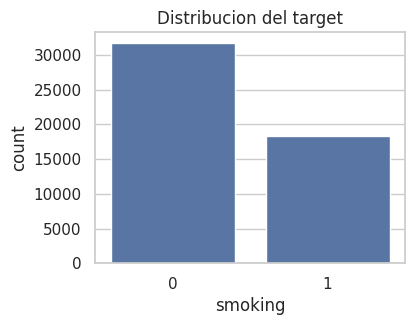

In [19]:
conteo = df[TARGET].value_counts()
prop = df[TARGET].value_counts(normalize=True)
print(pd.DataFrame({"filas": conteo, "proporcion": prop.round(4)}))
print(f"\nMedia = p(fumador) = {df[TARGET].mean():.4f} | varianza p(1-p) = {df[TARGET].var():.4f}")

fig, ax = plt.subplots(figsize=(4, 3))
sns.countplot(data=df, x=TARGET, ax=ax)
ax.set_title("Distribucion del target")
plt.show()

Hay un desbalance moderado: ~37% de fumadores. No es un caso extremo, pero tiene consecuencias para el modelado:
- **Accuracy engaña:** predecir siempre `0` daría ~63% de accuracy y F1 = 0. Como la métrica es F1 de la clase 1, hay que mirar precision y recall de esa clase.
- Conviene **estratificar** el split (`stratify=y`) y usar `random_state` fijo (buenas prácticas de clase).
- Se puede tantear `class_weight` y el **umbral de decisión** más adelante (notebooks 04 y 05).

## 5. Descripción de las variables

Se separan por tipo para mirarlas con las medidas que corresponden (tendencia central y dispersión en numéricas, frecuencias en categóricas).

In [20]:
cat_cols = df.select_dtypes(include="object").columns.tolist()
num_cols = [c for c in df.select_dtypes(include="number").columns if c not in (ID_COL, TARGET)]
print("Categoricas:", cat_cols)
print("Numericas:  ", len(num_cols))

Categoricas: ['gender', 'oral', 'tartar']
Numericas:   22


In [26]:
df[num_cols].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 22 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   age                  50000 non-null  int64  
 1   height(cm)           50000 non-null  int64  
 2   weight(kg)           50000 non-null  int64  
 3   waist(cm)            50000 non-null  float64
 4   eyesight(left)       50000 non-null  float64
 5   eyesight(right)      50000 non-null  float64
 6   hearing(left)        50000 non-null  float64
 7   hearing(right)       50000 non-null  float64
 8   systolic             50000 non-null  float64
 9   relaxation           50000 non-null  float64
 10  fasting blood sugar  50000 non-null  float64
 11  Cholesterol          50000 non-null  float64
 12  triglyceride         50000 non-null  float64
 13  HDL                  50000 non-null  float64
 14  LDL                  50000 non-null  float64
 15  hemoglobin           50000 non-null 

### Categóricas

In [23]:
for c in cat_cols:
    tabla = pd.concat([
        df[c].value_counts(normalize=True).rename("train"),
        df_entrega[c].value_counts(normalize=True).rename("entrega"),
        df.groupby(c)[TARGET].mean().rename("tasa fumadores (train)"),
    ], axis=1).round(3)
    print(f"--- {c}"); display(tabla)

--- gender


,train,entrega,tasa fumadores (train)
gender,,,
M,0.636,0.635,0.552
F,0.364,0.365,0.043


--- oral


,train,entrega,tasa fumadores (train)
oral,,,
Y,1.0,1.0,0.367


--- tartar


,train,entrega,tasa fumadores (train)
tartar,,,
Y,0.556,0.554,0.410
N,0.444,0.446,0.313


- `gender`: la tasa de fumadores es muy distinta entre hombres y mujeres (~55% vs ~4%). Va a ser una variable muy fuerte. Es una **señal real del dataset**, no una fuga.
- `oral` vale `Y` en todas las filas: **constante**, se descarta en el preprocesamiento.
- `tartar` tiene proporciones parecidas en train y entrega.

## 6. Train vs entrega

El modelo se entrena con un archivo y predice sobre otro. Si las distribuciones difieren mucho (**data drift**), el rendimiento real puede ser peor que el de validación. Se compara la media de cada numérica en ambos conjuntos, en unidades de desvío estándar de train.

In [24]:
comp = pd.DataFrame({
    "media train": df[num_cols].mean(),
    "media entrega": df_entrega[num_cols].mean(),
})
comp["dif (en desvios)"] = ((comp["media entrega"] - comp["media train"]) / df[num_cols].std()).round(3)
comp.sort_values("dif (en desvios)", key=abs, ascending=False).round(4)

,media train,media entrega,dif (en desvios)
eyesight(left),0.0284,0.0291,0.027
AST,1.0932,1.0713,-0.026
ALT,1.1293,1.1015,-0.021
Gtp,1.6681,1.6342,-0.016
waist(cm),3.4149,3.4093,-0.014
relaxation,3.1673,3.1628,-0.011
weight(kg),65.8787,65.7440,-0.010
triglyceride,5.2751,5.3008,0.009
HDL,2.3875,2.3832,-0.007
hemoglobin,0.5938,0.5933,-0.007


Las diferencias son chicas (la mayor es ≈ 0,03 desvíos), así que el archivo de entrega parece muestreado de la misma población. Los IDs de entrega (27358-55691) se intercalan con los de train (0-55690). Es decir, vienen del mismo conjunto original repartido en dos archivos.

## 7. Primera mirada a las relaciones con el target

Esto no reemplaza al EDA (notebook 02). Es solo un chequeo rápido de **posible fuga de información**: una variable con correlación casi perfecta con el target sería sospechosa.

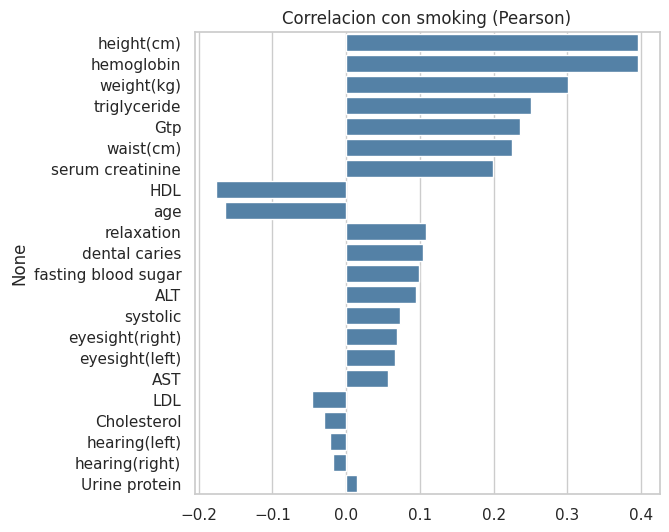

height(cm)          0.396
hemoglobin          0.396
weight(kg)          0.301
triglyceride        0.251
Gtp                 0.236
waist(cm)           0.225
serum creatinine    0.199
HDL                -0.177
Name: smoking, dtype: float64

In [25]:
corr = df[num_cols + [TARGET]].corr()[TARGET].drop(TARGET).sort_values(key=abs, ascending=False)
fig, ax = plt.subplots(figsize=(6, 6))
sns.barplot(x=corr.values, y=corr.index, ax=ax, color="steelblue")
ax.set_title("Correlacion con smoking (Pearson)")
plt.show()
corr.round(3).head(8)

La correlación más alta es moderada (≈ 0,40, `height(cm)` y `hemoglobin`). **No hay ninguna variable sospechosa de fuga** (ninguna "contiene" el resultado). Todas son mediciones de un chequeo de salud que existirían antes de saber si la persona fuma.

Las más asociadas al target son altura, hemoglobina, peso, triglicéridos y GTP. Altura y peso reflejan en parte el efecto del sexo (`gender`), ya que los hombres fuman mucho más en esta muestra.

## 8. Conclusiones del discovery

| Aspecto | Hallazgo | Decisión para las siguientes notebooks |
|---|---|---|
| Tamaño | 50.000 filas × 27 columnas (train); 5.692 × 26 (entrega) | Alcanza para entrenar y validar con holdout o CV |
| Esquema | El de entrega tiene las mismas columnas que train, menos `smoking` | El mismo pipeline sirve para ambos |
| Nulos / duplicados | 0 nulos, 0 duplicados reales | Sin imputación necesaria (verificar en 03) |
| `ID` | Identificador único | **Excluir** del modelo |
| `oral` | Constante (`Y`) | **Descartar** |
| Categóricas | `gender`, `tartar` (a codificar) | Encoding en el pipeline (03) |
| Escala | Variables clínicas reescaladas por un factor común (÷24) | Escalar si el modelo lo requiere (KNN, logística) |
| Target | ~37% de fumadores | Split estratificado, `random_state` fijo, métrica F1 clase 1, revisar umbral |
| Fuga | No se detectó | Mantener el mismo criterio en todo el pipeline |
| Drift | Train y entrega parecidos | Esperable que la validación sea representativa |

